In [18]:
import scanpy as sc
import scprep
import pandas as pd
import phate
import anndata

In [6]:
data_ya = sc.read_h5ad("../data/YA-7-CP_anndata.h5ad")

In [7]:
data_ya

AnnData object with n_obs × n_vars = 58459 × 24931
    obsm: 'X_spatial', 'spatial'

<Axes: xlabel='Library size', ylabel='Number of cells'>

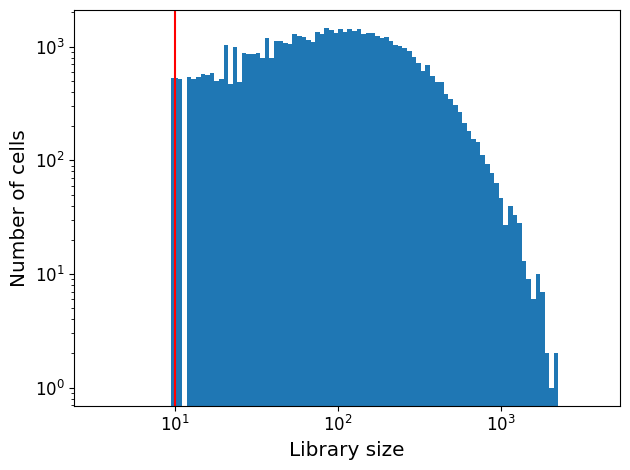

In [9]:
scprep.plot.plot_library_size(data_ya.X, cutoff=10)

In [23]:
X_filt = data_ya.X
var_filt = data_ya.var.index
obs_filt = data_ya.obs.index
obsm_X_spatial_filt = data_ya.obsm['X_spatial']
obsm_spatial_filt = data_ya.obsm['spatial']
# X_filt, obs_filt, obsm_X_spatial_filt, obsm_spatial_filt = scprep.filter.filter_library_size(X_filt, obs_filt, obsm_X_spatial_filt, obsm_spatial_filt, cutoff=10, keep_cells='above')
X_filt, var_filt = scprep.filter.filter_rare_genes(X_filt, var_filt, min_cells=10)

<Axes: xlabel='Library size', ylabel='Number of cells'>

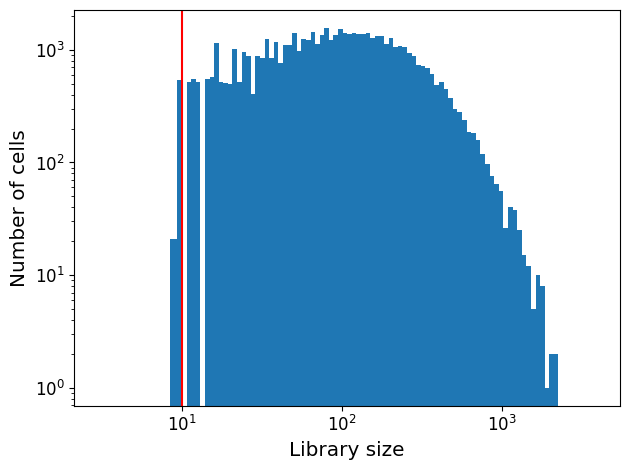

In [14]:
scprep.plot.plot_library_size(X_filt, cutoff=10)

In [15]:
X_filt = scprep.transform.sqrt(X_filt)

<Axes: xlabel='Library size', ylabel='Number of cells'>

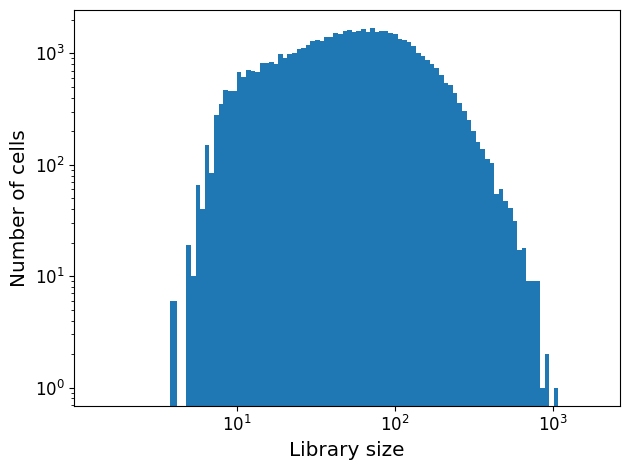

In [16]:
scprep.plot.plot_library_size(X_filt)

In [19]:
adata = anndata.AnnData(X=X_filt, obs=pd.DataFrame(index=obs_filt), var=pd.DataFrame(index=var_filt))

In [24]:
adata.obsm['X_spatial'] = obsm_X_spatial_filt
adata.obsm['spatial'] = obsm_spatial_filt

In [20]:
phate_operator = phate.PHATE()
X_phate = phate_operator.fit_transform(X_filt)
adata.obsm['X_phate'] = X_phate

Calculating PHATE...
  Running PHATE on 58459 observations and 14302 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 7.80 seconds.
    Calculating KNN search...
    Calculated KNN search in 991.94 seconds.
    Calculating affinities...
    Calculated affinities in 206.00 seconds.
  Calculated graph and diffusion operator in 1205.99 seconds.
  Calculating landmark operator...
    Calculating SVD...
    Calculated SVD in 14.63 seconds.
    Calculating KMeans...
    Calculated KMeans in 15.00 seconds.
  Calculated landmark operator in 32.30 seconds.
  Calculating optimal t...
    Automatically selected t = 28
  Calculated optimal t in 5.72 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 2.43 seconds.
  Calculating metric MDS...
  Calculated metric MDS in 5.66 seconds.
Calculated PHATE in 1252.12 seconds.


<Axes: title={'center': 'A23-290-CP'}, xlabel='PHATE 1', ylabel='PHATE 2'>

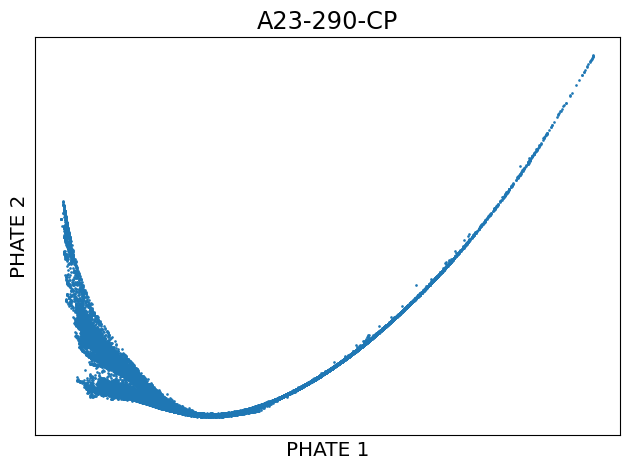

In [21]:
scprep.plot.scatter2d(adata.obsm['X_phate'], ticks=False, label_prefix='PHATE ', title='A23-290-CP')

In [26]:
adata.write_h5ad("../data/YA-7-CP_preprocessed.h5ad")